# Scratch Space

In [4]:
import numpy as np
import pandas as pd
import math
import tqdm
import itertools
from functools import cache

In [ ]:
M = 10**9 + 7
class Solution:
    @cache
    def _fact(self, n:int) -> int:
        if n == 0: return 1
        return n * self._fact(n-1) #% M

    def brute_force(self, n:int, k:int, show=False):
        nums = list(range(1,n+1))

        res = 0
        for perm in itertools.permutations(nums):
            curr_max = 0
            visible = 0
            for p in perm:
                if p > curr_max:
                    visible += 1
                    curr_max = p

            if visible == k:
                res += 1
                if show: print(perm)

        return res

    @cache
    def rearrangeSticks(self, n: int, k: int) -> int:
        if n == k: return 1
    
        # = Sum[i=0->n-1] nCr(n-1,i) * rearrangeSticks(i,k-1) * (n-i-1)!
        opts = 0 
        for i in range(n):
            left_combs = math.comb(n-1, i)                  #% M
            left_valid = self.rearrangeSticks(i, k-1)       #% M
            right_combs = self._fact(n-i-1)                 #% M
            opts += left_combs * left_valid * right_combs

        return opts #% M

    @cache
    def RS_opt(self, n: int, k: int) -> int:
        if n == k: return 1
        if k == 1: return self._fact(n-1)
        return (n-1) * self.RS_opt(n-1,k) + self.RS_opt(n-1,k-1)



In [10]:
print(sol.rearrangeSticks(5,3))
print(sol.RS_opt(5,3))

35
35


In [9]:
sol = Solution()
# test = (400,3)

# sol.rearrangeSticks(*test)
# uncached:         6.9s
# cached factorial: 6.4s
# cached main:      0.0s
# fully cached:     0.0s

# factorial is not the bottleneck

In [ ]:
# try a bunch of n,k; is there a pattern?

raw_res = dict()
for n in range(1,20):
    a = np.asarray([ sol.rearrangeSticks(n,k) for k in range(1,n+1) ])
    raw_res[n] = a

# sum[k=1->n](n,k) = (n+1)!
# the largest value seems to always be k=3?

(-0.01, 0.51)

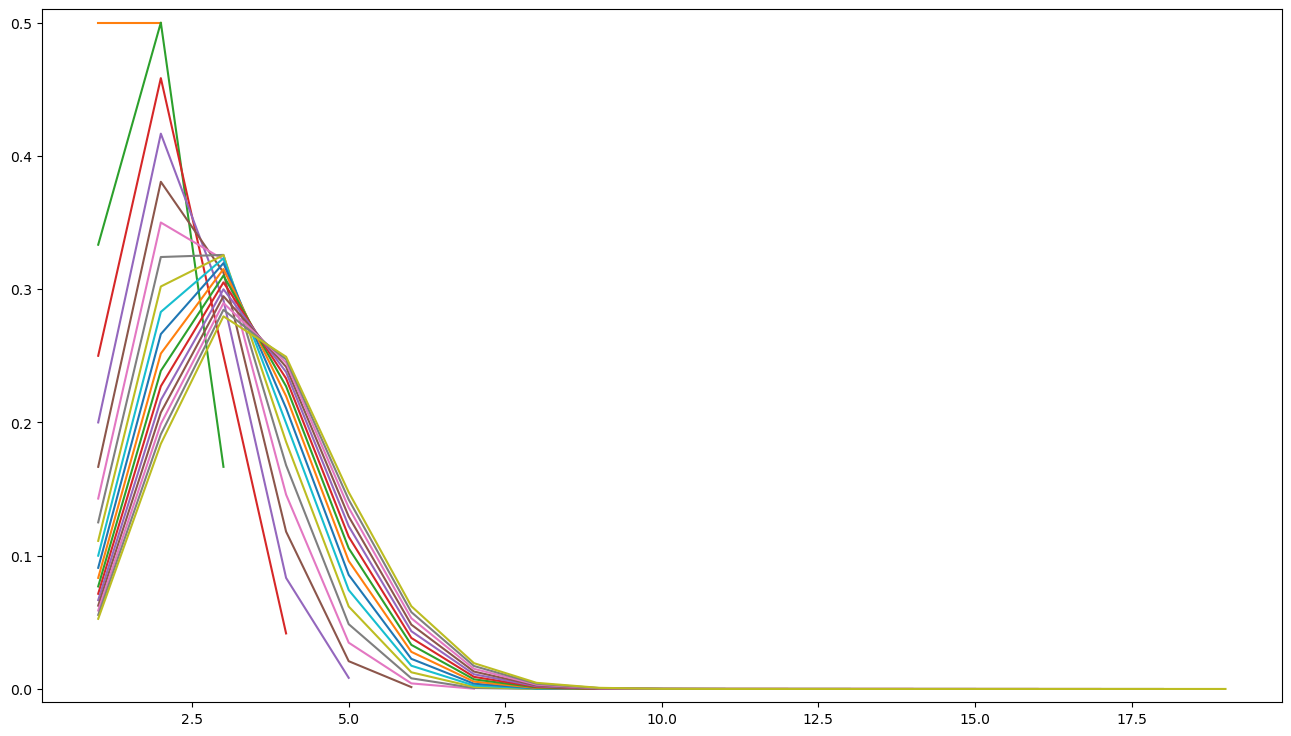

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16,9))
# ax2 = ax.twinx()

# max_val = list()
# max_idx = list()

for n in raw_res:
    k_ = np.arange(n)+1
    s = sol._fact(n)
    ax.plot(k_,raw_res[n]/s)

ax.set_ylim([-0.01, 0.51])

In [17]:
# is there a better pattern from looking at fixed k and moving n?

RES = np.zeros(shape=(20,20), dtype=np.int64)
for n in range(1,20):
    for k in range(1,n+1):
        RES[n,k] = sol.rearrangeSticks(n,k)
# f(n,k=1)   = n!
# f(n,k=n)   = n
# f(n,k=n-1) = Tri(n) = n(n+1)/2

COMBS = np.zeros_like(RES)
for n in range(1,20):
    for k in range(1,n+1):
        COMBS[n,k] = math.comb(n,k)

DIVS = np.zeros_like(RES)
REMS = np.zeros_like(RES)

for n in range(1,20):
    for k in range(1,n+1):
        d, r = divmod(RES[n,k], COMBS[n,k])
        DIVS[n,k] = d
        REMS[n,k] = r

In [19]:
nr = 9
# RES[1:nr+1, 1:nr+1]
for n in range(1,nr+1):
    for k in range(1, nr+1):
        print(f'({n},{k})={DIVS[n,k]:6d},{REMS[n,k]:6d}   ', end = ' ')
    print()

(1,1)=     1,     0    (1,2)=     0,     0    (1,3)=     0,     0    (1,4)=     0,     0    (1,5)=     0,     0    (1,6)=     0,     0    (1,7)=     0,     0    (1,8)=     0,     0    (1,9)=     0,     0    
(2,1)=     0,     1    (2,2)=     1,     0    (2,3)=     0,     0    (2,4)=     0,     0    (2,5)=     0,     0    (2,6)=     0,     0    (2,7)=     0,     0    (2,8)=     0,     0    (2,9)=     0,     0    
(3,1)=     0,     2    (3,2)=     1,     0    (3,3)=     1,     0    (3,4)=     0,     0    (3,5)=     0,     0    (3,6)=     0,     0    (3,7)=     0,     0    (3,8)=     0,     0    (3,9)=     0,     0    
(4,1)=     1,     2    (4,2)=     1,     5    (4,3)=     1,     2    (4,4)=     1,     0    (4,5)=     0,     0    (4,6)=     0,     0    (4,7)=     0,     0    (4,8)=     0,     0    (4,9)=     0,     0    
(5,1)=     4,     4    (5,2)=     5,     0    (5,3)=     3,     5    (5,4)=     2,     0    (5,5)=     1,     0    (5,6)=     0,     0    (5,7)=     0,     0    (5,8)= 

In [243]:
def get_diag_elems(delta:int):
    d = abs(delta)
    return np.diag(RES, -d)[1:]

a = get_diag_elems(3)
for p in range(20):
    diff_arr = np.diff(a, p)
    if (diff_arr == 0).all():
        print(f'Polynomial Order: {p-1}')
        break

Polynomial Order: 6


In [267]:
order = 4

Pd2 = np.polynomial.polynomial.Polynomial([1])
print(Pd2)
for p in range(order):
    Pd2 *= np.polynomial.polynomial.Polynomial([ p, 1 ])
    print(Pd2)
    print(Pd2.coef)
    print(RES[p+1, :p+2])

Pd2

1.0
0.0 + 1.0·x
[0. 1.]
[0 1]
0.0 + 1.0·x + 1.0·x²
[0. 1. 1.]
[0 1 1]
0.0 + 2.0·x + 3.0·x² + 1.0·x³
[0. 2. 3. 1.]
[0 2 3 1]
0.0 + 6.0·x + 11.0·x² + 6.0·x³ + 1.0·x⁴
[ 0.  6. 11.  6.  1.]
[ 0  6 11  6  1]


Polynomial([ 0.,  6., 11.,  6.,  1.], domain=[-1.,  1.], window=[-1.,  1.], symbol='x')

In [11]:
for k in range(1,6):
    a = sol.rearrangeSticks(5,k)
    b = sol.RS_opt(5,k)
    print(f'{k} | {a:3d} {b:3d}')

1 |  24  24
2 |  50  50
3 |  35  35
4 |  10  10
5 |   1   1


In [13]:
sol.RS_opt(481,314) %M

739606798

In [2]:
eval('list(range(1,11))')

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [11]:
def sum_of_powers(R, p):
    x = np.arange(1,R+1)
    x = np.pow(x, p)
    return np.cumsum(x)

sum_of_powers(5, 2)

R = 5
p = 2
for i,cs in enumerate(sum_of_powers(R, p)):
    k = i+1
    t = k*(k+1)*(2*k+1)//6
    print(f'{k=} | {cs:3d} {t:3d} {t==cs}')

k=1 |   1   1 True
k=2 |   5   5 True
k=3 |  14  14 True
k=4 |  30  30 True
k=5 |  55  55 True
